In [1]:
import joblib, numpy as np, pandas as pd

bundle = joblib.load("../models/lgbm_flow.joblib")
print("Type :", type(bundle))
if isinstance(bundle, dict):
    print("Clés :", list(bundle.keys()))

gold = pd.read_parquet("../data/gold_ml_entrant.parquet")
print("Gold :", gold.shape)
print(gold.columns.tolist())

c:\Users\asus\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle estimator LabelEncoder from version 1.6.1 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


Type : <class 'dict'>
Clés : ['model', 'features', 'num', 'cat', 'threshold', 'trained_until']
Gold : (981662, 43)
['flow_id', 'ts', 'date', 'source_file', 'src_ip', 'dest_ip', 'src_port', 'dest_port', 'proto', 'app_proto', 'state', 'reason', 'pkts_toserver', 'pkts_toclient', 'bytes_toserver', 'bytes_toclient', 'age', 'bytes_ratio', 'pkts_total', 'hour', 'dow', 'ip_prev_alerts', 'ip_gap_s', 'hist_flows', 'hist_alerted', 'hist_alert_rate', 'is_new_host', 'prev1h_flows', 'prev1h_alerted', 'prev1h_ports', 'n_alerts', 'sig', 'sig_category', 'sig_severity', 'label_v1', 'label_v2', 'label', 'has_http', 'method', 'url', 'user_agent', 'status', 'text']


In [2]:
import re, warnings
warnings.filterwarnings("ignore", category=UserWarning)

model, FEATS, NUM, CAT = bundle["model"], bundle["features"], bundle["num"], bundle["cat"]
print("Variables du modèle :", len(FEATS), "| numériques :", len(NUM), "| catégorielles :", CAT)
print("Seuil :", bundle["threshold"], "| entraîné jusqu'au :", bundle["trained_until"])
print("\nToutes les colonnes Gold :", gold.columns.tolist())

# Même découpage que le notebook 06 : fichier 008 exclu, tri chronologique, 20 % les plus récents = test
g = gold[~gold["source_file"].astype(str).str.contains("008")]
g = g.sort_values("ts", kind="mergesort").reset_index(drop=True)
te = g.iloc[int(len(g) * 0.8):].reset_index(drop=True)
print("\nAlertes de test :", len(te), "(attendu : 196 290)")

# Mêmes variables que l'entraînement : one-hot, noms nettoyés, colonnes alignées sur FEATS
X_te = pd.get_dummies(te[NUM + CAT], columns=CAT, dummy_na=True).astype("float32").fillna(0)
X_te.columns = [re.sub(r"[^0-9a-zA-Z_]", "_", c) for c in X_te.columns]
manquantes = [c for c in FEATS if c not in X_te.columns]
X_te = X_te.reindex(columns=FEATS, fill_value=0)
print("Colonnes du modèle absentes du test (mises à 0) :", manquantes)

# Contrôle : mêmes probabilités que predictions_test.parquet ?
p = model.predict_proba(X_te)[:, 1]
pred = pd.read_parquet("../data/predictions_test.parquet")
print("\nColonnes de predictions_test :", pred.columns.tolist())

Variables du modèle : 35 | numériques : 19 | catégorielles : ['proto', 'app_proto', 'state', 'reason']
Seuil : 0.4784211759514671 | entraîné jusqu'au : 2024-12-22 13:18:31.240621+00:00

Toutes les colonnes Gold : ['flow_id', 'ts', 'date', 'source_file', 'src_ip', 'dest_ip', 'src_port', 'dest_port', 'proto', 'app_proto', 'state', 'reason', 'pkts_toserver', 'pkts_toclient', 'bytes_toserver', 'bytes_toclient', 'age', 'bytes_ratio', 'pkts_total', 'hour', 'dow', 'ip_prev_alerts', 'ip_gap_s', 'hist_flows', 'hist_alerted', 'hist_alert_rate', 'is_new_host', 'prev1h_flows', 'prev1h_alerted', 'prev1h_ports', 'n_alerts', 'sig', 'sig_category', 'sig_severity', 'label_v1', 'label_v2', 'label', 'has_http', 'method', 'url', 'user_agent', 'status', 'text']

Alertes de test : 196290 (attendu : 196 290)
Colonnes du modèle absentes du test (mises à 0) : ['app_proto_http2', 'reason_shutdown']

Colonnes de predictions_test : ['flow_id', 'ts', 'src_ip', 'dest_ip', 'dest_port', 'proto', 'app_proto', 'label',

In [3]:
import shap

# 1) Contrôle : nos probabilités = p_flux du notebook 06 ?
chk = pd.DataFrame({"flow_id": te["flow_id"].values, "p_local": p}).merge(
    pred[["flow_id", "p_flux"]], on="flow_id", how="inner")
diff = (chk["p_local"] - chk["p_flux"]).abs()
print(f"Alertes comparées : {len(chk):,} | écart max : {diff.max():.2e} | écart moyen : {diff.mean():.2e}")

# 2) SHAP sur un échantillon stratifié de 20 000 alertes de test (le calcul sur 196 290 serait long)
rng = np.random.RandomState(42)
idx = np.concatenate([rng.choice(np.where(te["label"].values == k)[0], 10_000, replace=False) for k in (0, 1)])
X_s = X_te.iloc[idx]
explainer = shap.TreeExplainer(model)
sv = explainer.shap_values(X_s)
sv = sv[1] if isinstance(sv, list) else sv          # selon la version : liste [classe 0, classe 1] ou tableau
print("Valeurs SHAP :", sv.shape)

# 3) Importance globale = moyenne des |SHAP| par variable
imp = pd.Series(np.abs(sv).mean(axis=0), index=FEATS).sort_values(ascending=False)
print("\nTop 15 des variables (importance SHAP moyenne) :")
print(imp.head(15).round(4).to_string())

c:\Users\asus\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Alertes comparées : 196,290 | écart max : 2.22e-16 | écart moyen : 4.30e-20
Valeurs SHAP : (20000, 35)

Top 15 des variables (importance SHAP moyenne) :
bytes_toserver     1.1304
hist_alert_rate    0.9695
bytes_toclient     0.7073
bytes_ratio        0.6179
pkts_toserver      0.5931
pkts_toclient      0.5577
hist_alerted       0.4945
prev1h_flows       0.4319
ip_prev_alerts     0.4001
dest_port          0.3782
hist_flows         0.3406
age                0.2630
app_proto_http     0.2494
ip_gap_s           0.1917
prev1h_alerted     0.1800


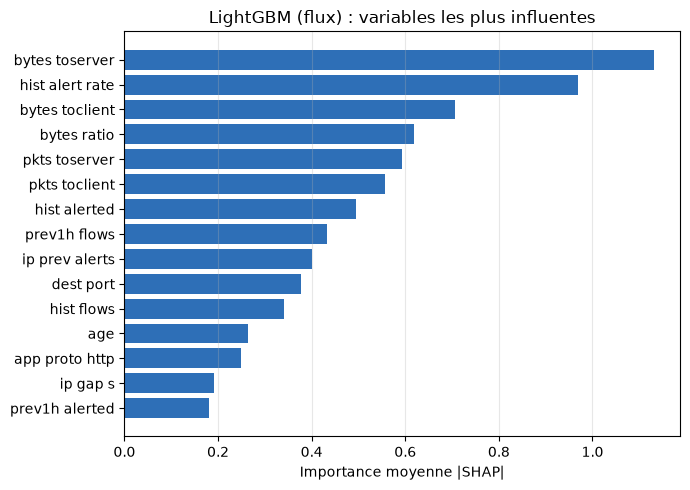

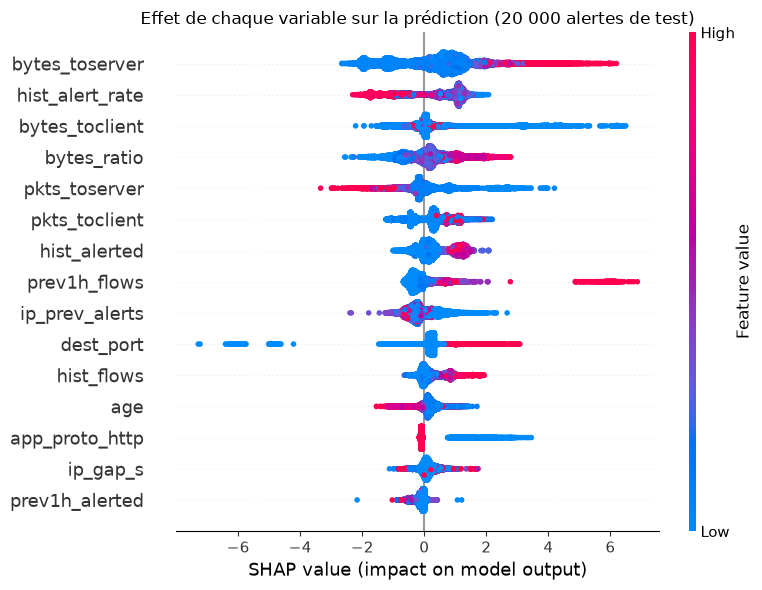

Figures et run MLflow enregistrés.


In [4]:
import matplotlib.pyplot as plt, mlflow
from pathlib import Path

OUT = Path("../reports"); OUT.mkdir(exist_ok=True)
noms = {c: c.replace("_", " ") for c in FEATS}

# Figure 1 : importance globale (barres)
plt.figure(figsize=(7, 5))
top = imp.head(15)[::-1]
plt.barh([noms[c] for c in top.index], top.values, color="#2E6FB7")
plt.xlabel("Importance moyenne |SHAP|"); plt.title("LightGBM (flux) : variables les plus influentes")
plt.grid(axis="x", alpha=.3); plt.tight_layout()
plt.savefig(OUT / "shap_importance.png", dpi=200, facecolor="white"); plt.show()

# Figure 2 : beeswarm (sens de l'effet : valeur haute/basse → pousse vers suspect/non suspect)
shap.summary_plot(sv, X_s, max_display=15, show=False, plot_size=(8, 6))
plt.title("Effet de chaque variable sur la prédiction (20 000 alertes de test)")
plt.tight_layout(); plt.savefig(OUT / "shap_beeswarm.png", dpi=200, facecolor="white"); plt.show()

imp.round(5).to_csv(OUT / "shap_importance.csv", header=["mean_abs_shap"])

# MLflow : expérience dédiée, avec un dossier d'artefacts local (la base vient de Kaggle)
mlflow.set_tracking_uri("sqlite:///../mlflow_final.db")
EXP = "suricata-explicabilite"
if mlflow.get_experiment_by_name(EXP) is None:
    mlflow.create_experiment(EXP, artifact_location=Path("../mlartifacts_local").resolve().as_uri())
mlflow.set_experiment(EXP)
with mlflow.start_run(run_name="SHAP LightGBM (flow)"):
    mlflow.log_params({"model": "suricata-lgbm-flow v1", "methode": "TreeExplainer",
                       "echantillon": "20000 alertes de test (10000 pos / 10000 neg)"})
    mlflow.log_metrics({f"shap_{c}": float(v) for c, v in imp.head(10).items()})
    for f in ["shap_importance.png", "shap_beeswarm.png", "shap_importance.csv"]:
        mlflow.log_artifact(str(OUT / f))
print("Figures et run MLflow enregistrés.")